# FoodLens — Models

Two ImageNet-pretrained **EfficientNet-B0** models are fine-tuned to classify Food-101's 101 dishes. They share the same backbone, data, hyperparameters, training loop and evaluation, and differ **only in the loss function**, so any difference between them (overall or across cuisines) can be attributed to the loss:

| | Model 1: Baseline | Model 2: Custom (fairness-aware) |
|---|---|---|
| Backbone | EfficientNet-B0 (ImageNet weights) | EfficientNet-B0 (ImageNet weights) |
| Classifier head | Dropout 0.2 → Linear 1280 → 101 | Dropout 0.2 → Linear 1280 → 101 |
| Hidden activations | SiLU (Swish) | SiLU (Swish) |
| Output | Softmax over 101 classes | Softmax over 101 classes |
| Loss | Cross-entropy | **Focal loss** (γ = 2) |

**Why focal loss?** Cross-entropy treats every training image equally. Focal loss scales each image's loss by (1 − p)^γ, where p is the probability the model gives the correct class, so images the model already gets right contribute almost nothing and **hard dishes dominate training**. This is our fairness-aware training: if some cuisines are harder for the model, focal loss pushes it to focus on them. Focal loss is also known to produce **better-calibrated confidence**, which our audit measures.

The output of this notebook is a CSV of test-set predictions and confidence scores for each model, which is the input to the cuisine audit.

## Setup

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import models, transforms
from sklearn.metrics import precision_recall_fscore_support

import sys
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src').is_dir())
sys.path.append(str(REPO_ROOT))
from src.data.food101_data import FoodDataset
from src.paths import CLEAN_INDEX, FOOD101_DIR, OUTPUTS_DIR

DEVICE = 'mps' if torch.backends.mps.is_available() else 'cpu'
torch.manual_seed(42)
print('Device:', DEVICE)

Device: mps


### Hyperparameters

`QUICK_TEST = True` trains on 10 classes for 1 epoch to check that everything runs and to estimate the full training time. Set it to `False` for the real run on all 101 classes.

In [2]:
QUICK_TEST = True

CONFIG = {
    'image_size': 224,       # input resolution expected by ImageNet models
    'batch_size': 64,
    'epochs': 1 if QUICK_TEST else 8,
    'optimizer': 'AdamW',
    'lr_backbone': 1e-4,     # small: pretrained weights only need gentle adjustment
    'lr_head': 1e-3,         # larger: the new classifier layer starts from random weights
    'weight_decay': 1e-4,
    'scheduler': 'cosine',   # learning rate decays smoothly to ~0 over training
    'focal_gamma': 2.0,
    'num_workers': 6,
}

OUT = OUTPUTS_DIR / ('quick_test' if QUICK_TEST else 'full')
OUT.mkdir(parents=True, exist_ok=True)
pd.Series(CONFIG)

image_size         224
batch_size          64
epochs               1
optimizer        AdamW
lr_backbone     0.0001
lr_head          0.001
weight_decay    0.0001
scheduler       cosine
focal_gamma        2.0
num_workers          6
dtype: object

## Data

Uses the cleaned index from the EDA notebook (duplicates removed, stratified validation split). Preprocessing matches the Data section: resize the shorter side to 256, center-crop 224×224, normalize with ImageNet mean/std. Training images also get **random resized crops, horizontal flips and mild color jitter**.

In [3]:
df = pd.read_csv(CLEAN_INDEX)
df['path'] = df['path'].map(lambda p: str(FOOD101_DIR / p))  # index stores paths relative to data/food-101

if QUICK_TEST:
    keep = sorted(df['label'].unique())[:10]
    df = df[df['label'].isin(keep)]

class_names = sorted(df['label'].unique())
df['target'] = df['label'].map({c: i for i, c in enumerate(class_names)})
NUM_CLASSES = len(class_names)

train_df, val_df, test_df = (df[df.split == s].reset_index(drop=True) for s in ['train', 'val', 'test'])
print(f'{NUM_CLASSES} classes | train {len(train_df)} | val {len(val_df)} | test {len(test_df)}')

10 classes | train 6750 | val 750 | test 2500


In [4]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(CONFIG['image_size'], scale=(0.5, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
eval_tf = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(CONFIG['image_size']),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

def make_loader(frame, tf, shuffle):
    return DataLoader(FoodDataset(frame, tf), batch_size=CONFIG['batch_size'], shuffle=shuffle,
                      num_workers=CONFIG['num_workers'], persistent_workers=True)

train_loader = make_loader(train_df, train_tf, shuffle=True)
val_loader = make_loader(val_df, eval_tf, shuffle=False)
test_loader = make_loader(test_df, eval_tf, shuffle=False)

## Model architecture

**EfficientNet-B0** (Tan & Le, 2019): a mobile-sized CNN built from inverted-residual (MBConv) blocks with squeeze-and-excitation attention, SiLU activations and batch normalization, ~4.1M parameters. Its small size makes it suitable for the FoodLens mobile app.

The ImageNet-pretrained convolutional layers are kept; only the final classification layer is replaced with a new one sized for our classes. The whole network is then fine-tuned, with a 10× higher learning rate on the new layer than on the pretrained layers.

Both models use this exact architecture. Using the same backbone isolates the effect of the loss function, which is the question our audit asks: *does fairness-aware training narrow the accuracy gap between cuisines?*

In [5]:
def build_efficientnet_b0(num_classes):
    model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
    model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_classes)
    return model, model.classifier

m, _ = build_efficientnet_b0(NUM_CLASSES)
print(f'EfficientNet-B0: {sum(p.numel() for p in m.parameters()) / 1e6:.1f}M parameters')
print(m.classifier)

EfficientNet-B0: 4.0M parameters
Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=10, bias=True)
)


## Loss functions

**Cross-entropy:** loss = −log(p), where p is the softmax probability of the correct class.

**Focal loss** (Lin et al., 2017): loss = −(1 − p)^γ · log(p). With γ = 2, an image the model already predicts with p = 0.9 contributes 100× less loss than under cross-entropy, while an image with p = 0.1 keeps almost all of its loss. γ = 0 gives plain cross-entropy.

In [6]:
class FocalLoss(nn.Module):
    def __init__(self, gamma=2.0):
        super().__init__()
        self.gamma = gamma

    def forward(self, logits, targets):
        log_p = F.log_softmax(logits, dim=1).gather(1, targets.unsqueeze(1)).squeeze(1)
        p = log_p.exp()
        return (-(1 - p) ** self.gamma * log_p).mean()

# Sanity check: easy example (p ≈ 0.9) vs hard example (p ≈ 0.1)
logits = torch.tensor([[2.2, 0.0], [-2.2, 0.0]]); t = torch.tensor([0, 0])
print('cross-entropy:', F.cross_entropy(logits, t, reduction='none').numpy().round(3))
print('focal (γ=2):  ', [round(FocalLoss()(logits[i:i+1], t[i:i+1]).item(), 3) for i in range(2)])

cross-entropy: [0.105 2.305]
focal (γ=2):   [0.001, 1.868]


## Training

In [7]:
def run_epoch(model, loader, loss_fn, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss, correct, seen = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            logits = model(x)
            loss = loss_fn(logits, y)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * len(y)
            correct += (logits.argmax(1) == y).sum().item()
            seen += len(y)
    return total_loss / seen, correct / seen


def train_model(name, builder, loss_fn):
    ckpt = OUT / f'{name}.pt'
    model, head = builder(NUM_CLASSES)
    model = model.to(DEVICE)
    if ckpt.exists():
        saved = torch.load(ckpt, map_location=DEVICE)
        model.load_state_dict(saved['weights'])
        print(f'Loaded trained {name} from {ckpt.relative_to(REPO_ROOT)}')
        return model, pd.DataFrame(saved['history'])

    head_ids = {id(p) for p in head.parameters()}
    optimizer = torch.optim.AdamW([
        {'params': [p for p in model.parameters() if id(p) not in head_ids], 'lr': CONFIG['lr_backbone']},
        {'params': head.parameters(), 'lr': CONFIG['lr_head']},
    ], weight_decay=CONFIG['weight_decay'])
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CONFIG['epochs'])

    history, best_acc = [], -1
    for epoch in range(1, CONFIG['epochs'] + 1):
        start = time.time()
        train_loss, train_acc = run_epoch(model, train_loader, loss_fn, optimizer)
        val_loss, val_acc = run_epoch(model, val_loader, loss_fn)
        scheduler.step()
        minutes = (time.time() - start) / 60
        history.append(dict(epoch=epoch, train_loss=train_loss, train_acc=train_acc,
                            val_loss=val_loss, val_acc=val_acc, minutes=minutes))
        print(f'{name} epoch {epoch}: train acc {train_acc:.3f} | val acc {val_acc:.3f} | {minutes:.1f} min')
        if val_acc > best_acc:
            best_acc = val_acc
            torch.save({'weights': model.state_dict(), 'history': history}, ckpt)

    best = torch.load(ckpt, map_location=DEVICE)
    model.load_state_dict(best['weights'])
    torch.save({'weights': best['weights'], 'history': history}, ckpt)
    return model, pd.DataFrame(history)

### Model 1: EfficientNet-B0 + cross-entropy (baseline)

In [8]:
baseline, baseline_hist = train_model('efficientnet_b0_ce', build_efficientnet_b0, nn.CrossEntropyLoss())

Loaded trained efficientnet_b0_ce from outputs/quick_test/efficientnet_b0_ce.pt


### Model 2: EfficientNet-B0 + focal loss (custom)

In [9]:
custom, custom_hist = train_model('efficientnet_b0_focal', build_efficientnet_b0, FocalLoss(CONFIG['focal_gamma']))

Loaded trained efficientnet_b0_focal from outputs/quick_test/efficientnet_b0_focal.pt


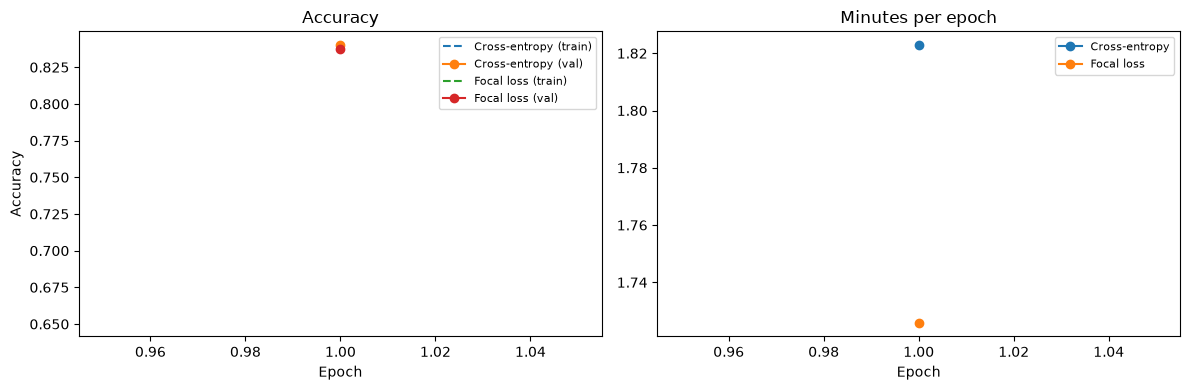

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, h in [('Cross-entropy', baseline_hist), ('Focal loss', custom_hist)]:
    axes[0].plot(h.epoch, h.train_acc, '--', label=f'{name} (train)')
    axes[0].plot(h.epoch, h.val_acc, '-o', label=f'{name} (val)')
    axes[1].plot(h.epoch, h.minutes, '-o', label=name)
axes[0].set(title='Accuracy', xlabel='Epoch', ylabel='Accuracy'); axes[0].legend(fontsize=8)
axes[1].set(title='Minutes per epoch', xlabel='Epoch'); axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

## Test-set predictions

For every test image we save the true label, the predicted label, the model's **confidence** (softmax probability of its prediction), the probability it gave the true class, and its top-5 predictions. These CSVs are the input to the cuisine audit. Full probability matrices are saved as `.npy` for calibration analysis.

In [11]:
@torch.no_grad()
def predict(model, loader):
    model.eval()
    return torch.cat([F.softmax(model(x.to(DEVICE)), dim=1).cpu() for x, _ in loader]).numpy()

def save_predictions(name, probs):
    pred = probs.argmax(1)
    top5 = np.argsort(-probs, axis=1)[:, :5]
    out = test_df[['id', 'label', 'name', 'target']].copy()
    out['pred_label'] = [class_names[i] for i in pred]
    out['confidence'] = probs.max(1)
    out['prob_true'] = probs[np.arange(len(probs)), test_df['target']]
    out['correct'] = pred == test_df['target'].values
    out['top5_correct'] = (top5 == test_df['target'].values[:, None]).any(1)
    out['top5'] = [' '.join(class_names[i] for i in row) for row in top5]
    out.to_csv(OUT / f'predictions_{name}.csv', index=False)
    np.save(OUT / f'probs_{name}.npy', probs)
    return out

preds = {
    'efficientnet_b0_ce': save_predictions('efficientnet_b0_ce', predict(baseline, test_loader)),
    'efficientnet_b0_focal': save_predictions('efficientnet_b0_focal', predict(custom, test_loader)),
}
print('Saved to', OUT.relative_to(REPO_ROOT))
preds['efficientnet_b0_focal'].head()

Saved to outputs/quick_test


,id,label,name,target,pred_label,confidence,prob_true,correct,top5_correct,top5
0,apple_pie/1011328,apple_pie,Apple pie,0,apple_pie,0.608962,0.608962,True,True,apple_pie bread_pudding baklava breakfast_burr...
1,apple_pie/101251,apple_pie,Apple pie,0,apple_pie,0.336755,0.336755,True,True,apple_pie bread_pudding baklava breakfast_burr...
2,apple_pie/1034399,apple_pie,Apple pie,0,apple_pie,0.415756,0.415756,True,True,apple_pie bread_pudding baklava breakfast_burr...
3,apple_pie/103801,apple_pie,Apple pie,0,bread_pudding,0.497660,0.409025,False,True,bread_pudding apple_pie beignets breakfast_bur...
4,apple_pie/1038694,apple_pie,Apple pie,0,apple_pie,0.538295,0.538295,True,True,apple_pie bread_pudding baklava breakfast_burr...


## Overall results

In [12]:
rows = []
for name, p in preds.items():
    prec, rec, f1, _ = precision_recall_fscore_support(p['target'], [class_names.index(c) for c in p['pred_label']],
                                                       average='macro', zero_division=0)
    rows.append({'model': name, 'top-1 accuracy': p['correct'].mean(), 'top-5 accuracy': p['top5_correct'].mean(),
                 'macro precision': prec, 'macro recall': rec, 'macro F1': f1,
                 'mean confidence': p['confidence'].mean()})
results = pd.DataFrame(rows).set_index('model').round(4)
results.to_csv(OUT / 'overall_results.csv')
results

,top-1 accuracy,top-5 accuracy,macro precision,macro recall,macro F1,mean confidence
model,,,,,,
efficientnet_b0_ce,0.8496,0.9964,0.8481,0.8496,0.8472,0.8186
efficientnet_b0_focal,0.8428,0.9952,0.8418,0.8428,0.8407,0.7197
